# Comparator (Fig. 15)

The comparator alone behind R_NODE / C_NODE, clocked as in the ADC: inputs step at +2 ns, `phi1` rises at +70 ns (PMOS latch released), `phi2` falls 2 ns later (NMOS latch connects), decision read 3 ns before the end of the 100 ns cycle. An SR latch on Q / Q-bar holds the decision through reset.

| Group | Input | Measures |
| --- | --- | --- |
| A | ±0.1 … 100 mV at the nominal common mode | delay vs overdrive |
| B | ±5 mV and ±1 mV at 0.6 … 1.3 V | common-mode range |
| C | −12 … +12 mV ramp in 0.25 mV steps, up and down | offset and hysteresis |

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sarlib import specs as S
from sarlib.analysis import load_cols, eng, window_around, Report

DATA = Path('simulation/comparator_tb.sch')
c = S.comparator
SP = c.SPECS
PLAN = S.comparator_plan()
HALF_LSB_MV = 0.5e3 * S.V_LSB_CMP
VDD = S.VDD
COLS = ['vsp', 'vsn', 'vinp', 'vinn', 'voutp', 'voutn', 'idd', 'vphi1', 'vphi2', 'vlat', 'vlatb', 'va', 'vb', 'vtail']
rep = Report()

def first_cross(t, y, level, rising, i0, i1):
    ys = y[i0:i1] - level
    idx = np.where((ys[:-1] < 0) & (ys[1:] >= 0))[0] if rising else np.where((ys[:-1] > 0) & (ys[1:] <= 0))[0]
    if idx.size == 0:
        return np.nan
    j = i0 + idx[0]
    return float(t[j] + (level - y[j]) / (y[j + 1] - y[j]) * (t[j + 1] - t[j]))

sgn = lambda x: 0 if x == 0 else (1 if x > 0 else -1)

## Per-cycle measurements

In [2]:
t, w = load_cols(DATA / 'tran_g.csv', COLS)
out, lat = w['voutp'] - w['voutn'], w['vlat'] - w['vlatb']
src_d = w['vsp'] - w['vsn']
vin_d = w['vinp'] - w['vinn']
ab = 0.5 * (w['va'] + w['vb'])
rows = []
for k, (g, vcm_p, vd_p) in enumerate(PLAN):
    t0, t1 = k * S.T_BIT, (k + 1) * S.T_BIT
    i0, i1 = np.searchsorted(t, t0), np.searchsorted(t, t1)
    te = first_cross(t, w['vphi1'], VDD / 2, True, i0 + int(0.3 * (i1 - i0)), i1)
    tcn = first_cross(t, w['vphi2'], VDD / 2, False, np.searchsorted(t, te - 5e-9), i1)
    pre, rst = (t >= te - 3e-9) & (t < te - 0.2e-9), (t >= te - 2e-9) & (t < te - 0.2e-9)
    ev = (t >= te) & (t < t1)
    final = out[(t >= t1 - c.SAMPLE_BEFORE_END - 1e-9) & (t < t1 - c.SAMPLE_BEFORE_END)].mean()
    dec = sgn(final) if abs(final) >= c.DEC_FRAC * VDD else 0
    ii = np.where(ev)[0]
    delay = {}
    for name, frac in (('t_d', c.DEC_FRAC), ('t_full', c.FULL_FRAC)):
        j = np.where(dec * out[ii] >= frac * VDD)[0]
        delay[name] = float(t[ii[j[0]]] - te) if dec and j.size else np.nan
    t_rst = first_cross(t, w['vphi2'], VDD / 2, True, np.searchsorted(t, t1 - 2e-9), np.searchsorted(t, t1 + 3e-9))
    tx = first_cross(t, dec * out, c.DEC_FRAC * VDD, False, np.searchsorted(t, t_rst - 0.3e-9), np.searchsorted(t, t1 + 20e-9))
    w_lat = (t >= t1 + 25e-9) & (t < t1 + 35e-9)
    lm = lat[w_lat].mean() if w_lat.sum() >= 2 else np.nan
    dp, dn = w['vinp'][ev] - w['vinp'][pre].mean(), w['vinn'][ev] - w['vinn'][pre].mean()
    cyc = (t >= t0) & (t < t1)
    q = float(np.trapezoid(w['idd'][cyc], t[cyc]))
    rows.append(dict(k=k, group=g, vcm_plan=vcm_p, vd_plan=vd_p, vd_meas=src_d[pre].mean(), t_eval=te, gap=tcn - te,
                     decision=dec, correct=(dec == sgn(vd_p)) if g in ('A', 'B') else np.nan, **delay,
                     t_hold=tx - t_rst, lat_ok=float((sgn(lm) if abs(lm) >= c.DEC_FRAC * VDD else 0) == dec) if np.isfinite(lm) else np.nan,
                     ab_cm=ab[rst].mean(), ab_diff=np.abs(w['va'] - w['vb'])[rst].mean(), pair_vds=(ab - w['vtail'])[rst].mean(),
                     reset_resid=out[rst].mean(), kick_diff=np.max(np.abs(dp - dn)), kick_cm=np.max(np.abs(0.5 * (dp + dn))),
                     kick_resid=abs(vin_d[pre].mean() - src_d[pre].mean()), e=VDD * q,
                     i_static=w['idd'][(t >= te - 20e-9) & (t < te - 2e-9)].mean()))
CY = pd.DataFrame(rows)
print(f"{len(CY)} cycles, {int((CY.decision == 0).sum())} undecided; phi1-to-phi2 gap {1e9 * CY.gap.median():.2f} ns")

250 cycles, 0 undecided; phi1-to-phi2 gap 2.00 ns


## Delay vs overdrive (group A)

regeneration time constant 0.06 ns; smallest overdrive right for both signs 0.1 mV


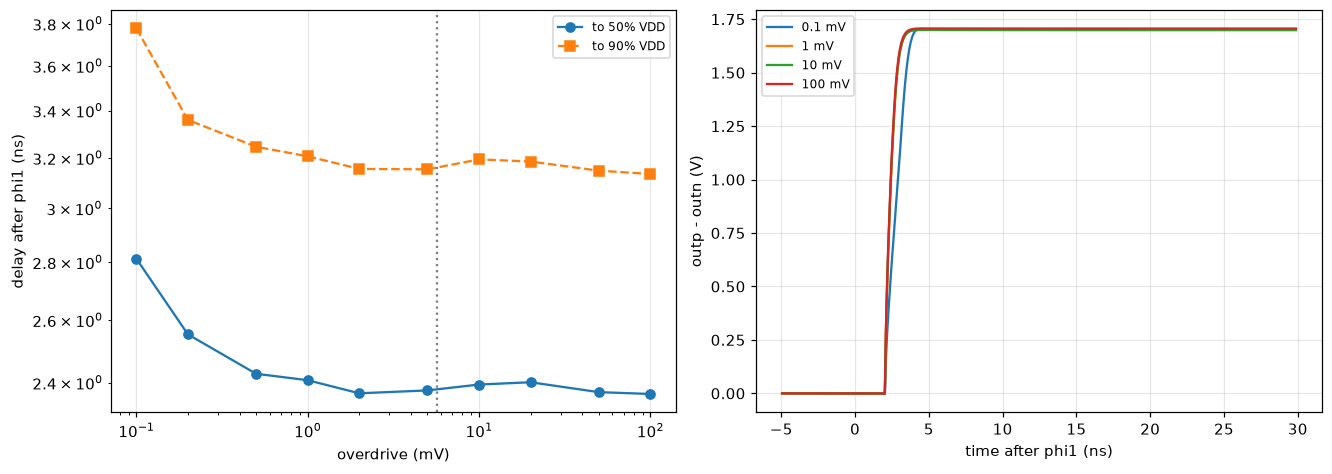

,overdrive_mV,both_right,td_ns,tfull_ns
0,0.1,True,2.813,3.777
1,0.2,True,2.553,3.359
2,0.5,True,2.427,3.246
3,1.0,True,2.408,3.207
4,2.0,True,2.368,3.155
5,5.0,True,2.376,3.154
6,10.0,True,2.394,3.194
7,20.0,True,2.401,3.185
8,50.0,True,2.371,3.148
9,100.0,True,2.365,3.135


In [3]:
A = CY[CY.group == 'A'].assign(mag_mv=lambda d: np.round(1e3 * np.abs(d.vd_plan), 4), sign=lambda d: np.sign(d.vd_plan).astype(int))
tab = A.pivot_table(index='mag_mv', columns='sign', values=['correct', 't_d', 't_full'], aggfunc='first')
mags = tab.index.values.astype(float)
both_ok = (tab[('correct', 1)] == 1).values & (tab[('correct', -1)] == 1).values
td_w = 1e9 * np.fmax(tab[('t_d', 1)].values, tab[('t_d', -1)].values)
tf_w = 1e9 * np.fmax(tab[('t_full', 1)].values, tab[('t_full', -1)].values)
good = both_ok & np.isfinite(td_w)
t_half = float(10 ** np.interp(np.log10(HALF_LSB_MV), np.log10(mags[good]), np.log10(td_w[good])))
fit = good & (mags <= 20.0)
tau = float(np.polyfit(np.log(1 / mags[fit]), td_w[fit], 1)[0])
ok_big = bool(both_ok[mags >= 1e3 * c.OVERDRIVE_B - 1e-9].all())
print(f'regeneration time constant {tau:.2f} ns; smallest overdrive right for both signs {mags[both_ok].min():g} mV')
rep.check(f'decisions right from {1e3 * c.OVERDRIVE_B:g} mV up', 'yes' if ok_big else 'no', 'yes', ok_big)
rep.limit(f'decision delay at half an LSB ({HALF_LSB_MV:.2f} mV)', t_half, '{:.2f} ns', SP['t_dec_ns_max'], '<=', 'ns')

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].loglog(mags[good], td_w[good], 'o-', label=f'to {c.DEC_FRAC:.0%} VDD')
ax[0].loglog(mags[good], tf_w[good], 's--', label=f'to {c.FULL_FRAC:.0%} VDD')
ax[0].axvline(HALF_LSB_MV, c='gray', ls=':'); ax[0].set(xlabel='overdrive (mV)', ylabel='delay after phi1 (ns)'); ax[0].legend(fontsize=8)
for _, r in A[(A.vd_plan > 0) & A.mag_mv.isin([0.1, 1.0, 10.0, 100.0])].iterrows():
    m = (t >= r.t_eval - 5e-9) & (t < (r.k + 1) * S.T_BIT)
    ax[1].plot(1e9 * (t[m] - r.t_eval), out[m], label=f'{r.mag_mv:g} mV')
ax[1].set(xlabel='time after phi1 (ns)', ylabel='outp - outn (V)'); ax[1].legend(fontsize=8)
plt.show()
pd.DataFrame(dict(overdrive_mV=mags, both_right=both_ok, td_ns=td_w, tfull_ns=tf_w)).round(3)

## Offset and hysteresis (group C)

The decision flips where V_in + V_os = 0; the two ramp directions bound the hysteresis (0.25 mV resolution).

flip up +0.12 mV, down -0.12 mV


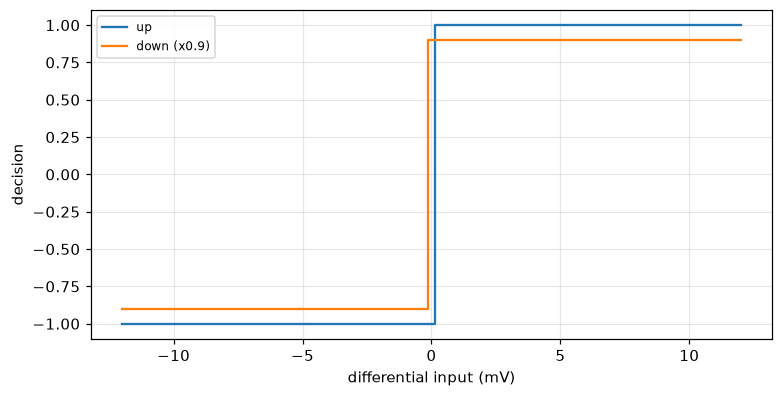

In [4]:
def flips(df):
    v, d = df.vd_meas.values, df.decision.values
    ch = np.where(np.diff(d) != 0)[0]
    return 0.5 * (v[ch[0]] + v[ch[0] + 1]), len(ch), v, d

f_up, n_up, vu, du = flips(CY[CY.group == 'C+'])
f_dn, n_dn, vdn, ddn = flips(CY[CY.group == 'C-'])
offset, hyst = -0.5 * (f_up + f_dn), f_up - f_dn
print(f'flip up {1e3 * f_up:+.2f} mV, down {1e3 * f_dn:+.2f} mV')
rep.limit('nominal offset', 1e3 * abs(offset), '{:.2f} mV', SP['offset_mv_max'], '<=', 'mV')
rep.limit('hysteresis', 1e3 * abs(hyst), '{:.2f} mV', SP['hyst_mv_max'], '<=', 'mV')
rep.check('one flip per ramp', f'{n_up} / {n_dn}', '1 / 1', n_up == 1 and n_dn == 1)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.step(1e3 * vu, du, where='mid', label='up'); ax.step(1e3 * vdn, 0.9 * ddn, where='mid', label='down (x0.9)')
ax.set(xlabel='differential input (mV)', ylabel='decision'); ax.legend(fontsize=8)
plt.show()

## Input common mode (group B)

In [5]:
B = CY[CY.group == 'B'].assign(dmv=lambda d: np.round(1e3 * d.vd_plan, 3))
rows = []
for vcm, g in B.groupby(np.round(B.vcm_plan, 3)):
    r = dict(vcm=vcm)
    for dmv in (5.0, -5.0, 1.0, -1.0):
        x = g[np.isclose(g.dmv, dmv)].iloc[0]
        r[f'ok {dmv:+g}'], r[f'td {dmv:+g} (ns)'] = x.correct == 1, 1e9 * x.t_d
    r['good'] = r['ok +5'] and r['ok -5'] and max(r['td +5 (ns)'], r['td -5 (ns)']) <= SP['t_dec_ns_max']
    rows.append(r)
CM = pd.DataFrame(rows)
rng = window_around(CM.vcm.values, CM.good.values, S.VCM_CMP)
rep.check('common-mode range with +/-5 mV right and delay in spec', 'none' if rng is None else f'{rng[0]:.2f} to {rng[1]:.2f} V',
          'covers 0.6 - 1.25 V', rng is not None and rng[0] <= 0.6 + 1e-9 and rng[1] >= 1.25)
CM.round(3)

,vcm,ok +5,td +5 (ns),ok -5,td -5 (ns),ok +1,td +1 (ns),ok -1,td -1 (ns),good
0,0.600,True,4.690,True,4.881,True,5.580,False,5.148,True
1,0.700,True,2.536,True,2.580,True,3.767,True,3.847,True
2,0.800,True,2.346,True,2.365,True,2.451,True,2.428,True
3,0.900,True,2.353,True,2.353,True,2.377,True,2.405,True
4,0.949,True,2.376,True,2.372,True,2.378,True,2.408,True
5,1.000,True,2.380,True,2.403,True,2.386,True,2.416,True
6,1.100,True,2.430,True,2.420,True,2.420,True,2.414,True
7,1.200,True,2.490,True,2.491,True,2.461,True,2.482,True
8,1.300,True,2.561,True,2.573,True,2.549,True,2.553,True


## Kickback, reset, capture and power

In [6]:
lat_ok = CY.lat_ok.dropna()
small = np.abs(CY.vd_plan) <= 12.01e-3
print(f"peak kick: differential {1e3 * CY.kick_diff.max():.2f} mV ({CY.kick_diff.max() / S.V_LSB_CMP:.2f} LSB), common mode {1e3 * CY.kick_cm.max():.2f} mV")
print(f"a/b level in reset {CY.ab_cm.median():.2f} V; decision outlasts the phi2 reset edge by {1e9 * CY.t_hold.min():.2f} ns")
print(f"static current {eng(CY.i_static.median(), 'A')}; energy per decision {eng(CY.e.mean(), 'J')} mean, {eng(CY.e.max(), 'J')} max")
rep.limit('input node error at the strobe', CY.kick_resid.max() / S.V_LSB_CMP, '{:.3f} LSB', SP['kick_resid_lsb_max'], '<=', 'LSB')
rep.info('peak differential kickback', f'{CY.kick_diff.max() / S.V_LSB_CMP:.2f} LSB')
rep.limit('Q - Q-bar left at the end of reset', 1e3 * np.abs(CY.reset_resid).max(), '{:.2f} mV', SP['reset_resid_mv_max'], '<=', 'mV')
rep.limit('a/b equalised in reset (|vd| <= 12 mV)', 1e3 * CY.ab_diff[small].max(), '{:.1f} mV', SP['reset_ab_mv_max'], '<=', 'mV')
rep.limit('input pair VDS in reset (worst common mode)', CY.pair_vds.min(), '{:.2f} V', SP['pair_vds_v_min'], '>=', 'V')
rep.check('SR latch holds the decision through reset', f'{int((lat_ok == 1).sum())} of {len(lat_ok)}', 'all', bool((lat_ok == 1).all()))
rep.info('static supply current', eng(CY.i_static.median(), 'A'))
rep.info('energy per decision (max)', eng(CY.e.max(), 'J'))

peak kick: differential 18.25 mV (1.62 LSB), common mode 13.73 mV
a/b level in reset 1.08 V; decision outlasts the phi2 reset edge by 0.06 ns
static current 21.1 uA; energy per decision 3.79 pJ mean, 3.98 pJ max


## Summary

In [7]:
rep.table()

,check,value,spec,result
0,decisions right from 5 mV up,yes,yes,PASS
1,decision delay at half an LSB (5.65 mV),2.38 ns,<= 15 ns,PASS
2,nominal offset,0.00 mV,<= 1 mV,PASS
3,hysteresis,0.25 mV,<= 0.5 mV,PASS
4,one flip per ramp,1 / 1,1 / 1,PASS
5,common-mode range with +/-5 mV right and delay...,0.60 to 1.30 V,covers 0.6 - 1.25 V,PASS
6,input node error at the strobe,0.000 LSB,<= 0.1 LSB,PASS
7,peak differential kickback,1.62 LSB,,INFO
8,Q - Q-bar left at the end of reset,0.00 mV,<= 20 mV,PASS
9,a/b equalised in reset (|vd| <= 12 mV),8.7 mV,<= 30 mV,PASS
